<CENTER>
    <a href="http://opendata.atlas.cern" class="icons"><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/raw/master/images/ATLASOD.gif" style="width:40%"></a>
</CENTER>

# Is this data any good? Comparing data-quality selections with ATLAS Open Data

Every physics result you have ever seen rests on a step that never appears in the published results: somebody
decided which  recorded collisions were trustworthy enough to use for physics studies and searches.

During LHC running periods the beams collide continuously, and ATLAS records the colission products (so called "data") continuously. Roughly the frequency of particle colissions is called "luminosity". During data taking sometimes problems can develop rending the corresponding time blocks useless. For example: a calorimeter module can start drawing noise or the High Voltage of some subsystem channels can drop or an event can be written to disk incompletely.Data taken during those periods (luminosity blocks) looks superficially like any other data, and could be used to produce results but the detector would be not fully functionable.

The standard defence is to create a **Good Runs List (GRL)**: an explicit list of luminosity blocks during which all relevant subsystems were verified -by the quality assurance- to be operating nominally.
Anything outside the list is discarded before physics analysis begins.

That defence is not free. It costs luminosity, namely results in eand where to draw the line is a judgement call rather
than a fact. So this notebook does something slightly unusual: instead of applying one selection and
moving on, it applies **three** and compares them.

## The question

Everything in this notebook is one question asked repeatedly, in different variables and different
parts of the detector:

> **Where do the three selections disagree, and does the disagreement look like physics or like
> a problem in some part of the detector?**

If all three give the same normalised distributions, the extra filtering is removing events without
changing the character of what survives. If one shows a bump, a tail, or a hotspot the others don't,
that excess is a direct picture of what the filter exists to catch.

## How we go looking

Three complementary views, because a detector problem that hides in one will often be obvious in
another:

* **Overlaid 1D distributions**, normalised to unit area. Since the three selections keep different
  numbers of events *by construction*, raw counts would only tell us what we already know.
  Normalising removes the trivial difference and leaves the interesting one — does the *shape* change?
  
* **Deliberately absurd ranges.** Missing transverse energy is plotted out to 5 TeV — far beyond
  anything physical. That is the point. A real event has MET of order tens of GeV; an event with a
  calorimeter noise burst can have thousands. The wide range is a trap set for events that should not
  exist, and the narrow ranges then check the physics region where the selections ought to agree.

Two independent data streams are examined: **dileptons**, where the Z peak at 91 GeV acts as a
calibration standard whose position and width can be compared between selections, and **QCD jets**,
where the sheer event rate makes rare pathologies statistically visible.

## Contents

[Getting the software](#setup) <br />
[Configuration flags](#config) <br />
[Three data-quality selections](#samples) <br />
[Overlaying the three selections](#p3) <br />
[Invariant mass](#mass) <br />
[Reading and selecting events](#processing) <br />
[Running everything](#run) <br />


<a id='setup'></a>

## Getting the software

Two packages that are usually not pre-installed:

* [**uproot**](https://uproot.readthedocs.io/) reads ROOT files in pure Python, with no ROOT
  installation required.
* [**atlasopenmagic**](https://github.com/atlas-outreach-data-tools/atlasopenmagic) knows where the
  Open Data files live, so we don't have to hard-code URLs.

This cell only needs running the first time you open the notebook on a given machine.

In [ ]:
# Only needed once per machine or session - skip on later runs.
!pip install -q atlasopenmagic
!pip install -q uproot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.8/405.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 698.7/698.7 kB 31.0 MB/s eta 0:00:00


We're going to be using a number of tools to help us:

uproot: lets us read .root files typically used in particle physics into data formats used in python

awkward: lets us use efficiently the nested data in columnar format

numpy: provides numerical calculations such as histogramming

matplotlib: common tool for making plots, figures, images, visualisations

tqdm: common tool for progress bars

atlasopenmagic (atom): The best tool for accessing Atlas Open Data data easily

In [ ]:
import uproot                          # for reading .root files
import awkward as ak                   # for handling variable-length event data
import numpy as np                     # for numerical operations and histogramming
import matplotlib.pyplot as plt        # for plotting
from matplotlib.ticker import AutoMinorLocator  # for minor ticks on plot axes
from matplotlib.colors import LogNorm  # for log-scale colour maps on 2D histograms
from tqdm import tqdm                  # for progress bars over large loops
import atlasopenmagic as atom          # for accessing Atlas Open Data data easily

<a id='config'></a>

## Configuration flags

This notebook is driven entirely by four single-letter switches at the top. Rather than editing code
in a dozen places, you change these and re-run — which is what makes it usable as a *scanning* tool,
sweeping over the different data streams to examine which ones look healthy and which ones don't.

| Flag | Meaning |
|---|---|
| `ty` | Which objects to look at: `'lep'`, `'jet'`, or `'both'` |
| `til` | Lepton flavour: `'e'`, `'mu'`, or `'lep'` for both |
| `tis` | Charge combination: `'op'` (opposite-sign) or `'ss'` (same-sign) |
| `tit` | Jet trigger `'J'` (single-jet) or `'met'` for met cuts |

In [ ]:
# Analysis configuration flags

ty = 'lep'   # object type to analyse: 'lep' (dileptons), 'jet' (QCD jets), or 'both'

til = 'both'   # lepton flavour: 'e' (electrons), 'mu' (muons), or 'lep' (both) - only used if ty involves leptons

tis = 'op'   # lepton pair charge combination: 'op' (opposite-sign) or 'ss' (same-sign)

tit = 'J'    # jet trigger to require: 'J' (single-jet) or 'met' for met cuts

lumi = 36000   # integrated luminosity, in pb^-1
fraction = 0.01   # fraction of events to process (1 = use all available data)

<a id='samples'></a>

## Three data-quality selections

Here is the concept the whole notebook is built around.

Not every collision ATLAS records is usable. Sometimes a calorimeter module is drawing noise, a
detector subsystem is out of the run, or an event is written out incompletely. Before anyone does
physics with the data, it is filtered — and the standard filter is the **Good Runs List (GRL)**,
an explicit list of luminosity blocks during which every subsystem
was confirmed to be operating nominally. Anything outside the GRL is thrown away.

That filter is not free. It costs luminosity, and the choice of what counts as "good enough" is a
judgement call. This notebook compares the GRL baseline against two alternative selections, labelled
**IG** and **IF**, to see what the different choices actually do to the data.

The question we are asking, over and over in different variables, is:

> **Where do the three selections disagree, and does the disagreement look like physics or like a problem in some part of the
> detector?**

If all three give identical normalised distributions, the extra filtering is removing events but not
changing the *character* of what survives. If one of them shows a bump, a tail, or a hotspot the
others don't, that excess is a direct picture of what the filter is there to catch.

########################################################

THE FOLLOWING  **`2bjets`** AND **`2to4lep`** WILL CHANGE WITH THE NEW RELEASE

########################################################

Two skims are loaded for each selection — **`2bjets`** for the QCD jet stream and **`2to4lep`** for the
dilepton stream — since the two object types come from different triggers and are compared separately.

In [ ]:
atom.set_release('2025e-13tev-beta')

#########################################################################
#                 This will change, with the new release                #
#########################################################################

# GRL data samples - the standard Good Runs List selection, our reference
data_samples_1 = atom.build_data_dataset('2bjets', name="qcdjets_GRL", protocol='https')
data_samples_2 = atom.build_data_dataset('2to4lep', name="2lep_GRL", protocol='https')

# IG data samples - first alternative selection
data_samples_3 = atom.build_data_dataset('2bjets', name="qcdjet_IG", protocol='https')
data_samples_4 = atom.build_data_dataset('2to4lep', name="2lep_IG", protocol='https')

# IF data samples - second alternative selection
data_samples_5 = atom.build_data_dataset('2bjets', name="qcdjets_IF", protocol='https')
data_samples_6 = atom.build_data_dataset('2to4lep', name="2lep_IF", protocol='https')

samples = {**data_samples_1, **data_samples_2,**data_samples_3, **data_samples_4,**data_samples_5, **data_samples_6}

Fetching metadata for release: 2025e-13tev-beta...
Fetching datasets: 100%|██████████| 374/374 [00:00<00:00, 662.06datasets/s]
✓ Successfully cached 374 datasets.
Active release: 2025e-13tev-beta. (Datasets path: REMOTE)
/tmp/ipykernel_800/2863964412.py:4: DeprecationWarning: The build_data_dataset function is deprecated. Use build_dataset with the appropriate data definitions instead.
  data_samples_1 = atom.build_data_dataset('2bjets', name="qcdjets_GRL", protocol='https')
/tmp/ipykernel_800/2863964412.py:5: DeprecationWarning: The build_data_dataset function is deprecated. Use build_dataset with the appropriate data definitions instead.
  data_samples_2 = atom.build_data_dataset('2to4lep', name="2lep_GRL", protocol='https')
/tmp/ipykernel_800/2863964412.py:8: DeprecationWarning: The build_data_dataset function is deprecated. Use build_dataset with the appropriate data definitions instead.
  data_samples_3 = atom.build_data_dataset('2bjets', name="qcdjet_IG", protocol='https')
/tmp/i

<a id='p3'></a>

## Overlaying the three selections

`p3` is the workhorse of the notebook: give it a variable name and a range, and it overlays GRL, IG
and IF on the same axes so you can see immediately where they part company.

The important detail is that each histogram is **normalised to unit area** before plotting. This is
deliberate. The three selections keep different numbers of events by construction — that is the whole
point of a filter — so comparing raw counts would only tell us what we already know. Normalising
removes the trivial difference and leaves the interesting one: *does the shape change?*

A shape difference means the filter is removing a specific kind of event, not just fewer events. That
is the signal we are hunting for.

The log y-axis matters here too. Data-quality problems live in the tails — a handful of pathological
events with absurd momentum or missing energy — and on a linear scale those are invisible next to a
bulk distribution millions of events tall.

In [ ]:
def p3(var, name, axis_name, low, high, NB, title,ww):
	bins = np.linspace(low, high, NB)
	bin_centers = (bins[:-1] + bins[1:]) / 2
	bin_width = bins[1] - bins[0]
	xerr = bin_width / 2
	def get_hist(DF):
		Hr = np.zeros(len(bins) - 1)
		for i in range(len(DF)):
			y = DF[i][f'{var}']
			y_np = np.asarray(y)
			hi, _ = np.histogram(y_np, bins=bins)
			Hr += hi
		return Hr
	if ww:
		DF1 = lepdata_GRL; DF2 = lepdata_IG; DF3 = lepdata_IF
	else:
		DF1 = qcddata_GRL; DF2 = qcddata_IG; DF3 = qcddata_IF

	Rr1 = get_hist(DF1); Rr2 = get_hist(DF2); Rr3 = get_hist(DF3)
	Hr1 = Rr1 / np.sum(Rr1); Hr2 = Rr2 / np.sum(Rr2); Hr3 = Rr3 / np.sum(Rr3)
	E1 = np.sqrt(Rr1)/np.sum(Rr1); E2 = np.sqrt(Rr2)/np.sum(Rr2); E3 =np.sqrt(Rr3)/ np.sum(Rr3)

	def ratio(ar, par):
		with np.errstate(divide='ignore', invalid='ignore'):
			r = np.where(par > 0, ar / par, 0)
			er = r / np.sqrt(np.where(ar > 0, ar, 0.0))
		return r, er

	r_IF, er_IF = ratio(Hr3, Hr1)   # IF  / GRL
	r_IG, er_IG = ratio(Hr2, Hr1)   # IG  / GRL

	fig, (ax, rax1, rax2) = plt.subplots(3, 1, sharex=True, figsize=(7, 8),gridspec_kw={'height_ratios': [3, 1, 1], 'hspace': 0.05})

	ax.errorbar(bin_centers, Hr1, yerr=E1, xerr=xerr, fmt='.', color='black',markersize=4, capsize=2, label=f'GRL')
	ax.errorbar(bin_centers, Hr2, yerr=E2, xerr=xerr, fmt='+', color='red',markersize=4, capsize=2, label=f'IG')
	ax.errorbar(bin_centers, Hr3, yerr=E3, xerr=xerr, fmt='x', color='blue',markersize=4, capsize=2, label=f'IF')
	ax.set_ylabel('Normalised counts')
	ax.set_yscale('log')
	ax.set_title(f'{title}')
	ax.legend()

	rax1.errorbar(bin_centers, r_IF, xerr=xerr, fmt='.',color='blue', markersize=4, capsize=2,label='IF/GRL')
	rax1.axhline(1.0, color='black', ls='--', lw=1)
	rax1.set_ylabel('IF / GRL')
	rax1.legend()

	rax2.errorbar(bin_centers, r_IG, xerr=xerr, fmt='.',color='red', markersize=4, capsize=2,label='IG/GRL')
	rax2.axhline(1.0, color='black', ls='--', lw=1)
	rax2.set_ylabel('IG / GRL')
	rax2.legend()
	rax2.set_xlabel(f'{axis_name}')

	for r in (rax1, rax2):
		r.grid(axis='y', alpha=0.3)

	ax.set_xlim(low, high)
	fig.savefig(f'plots/{name}', bbox_inches='tight')
	plt.show()
	return 0

<a id='mass'></a>

## Invariant mass

The invariant mass of a system of particles is the one quantity every observer agrees on, whatever
frame they are in. For a pair of leptons it comes straight from the relativistic energy-momentum
relation:

$$ m^2 = E^2 - |\vec{p}|^2 = \left(\sum_i E_i\right)^2 - \left|\sum_i \vec{p}_i\right|^2 $$

Note the order: sum the four-momenta *first*, then take the mass. Doing it the other way round gives
you something else entirely.

The components are built from the detector's natural coordinates. Transverse momentum and azimuth give
$p_x = p_T\cos\phi$ and $p_y = p_T\sin\phi$ directly. The longitudinal component uses the identity
$\theta = 2\arctan(e^{-\eta})$ relating pseudorapidity to polar angle, so that $p_z = p_T/\tan\theta$
— which is the same thing as the more familiar $p_T \sinh\eta$, just written in terms of what the
ntuple stores.

The `ak.where(Mass_2 > 0, ...)` guard handles a real effect, not a hypothetical one: finite detector
resolution can push a measured $E^2 - p^2$ slightly negative for a genuinely massless or near-massless
system, and taking the square root would give `NaN`. Setting those to zero keeps them in the histogram
where you can see them, at the bottom of the range.

**Why this matters for a data-quality study.** For opposite-sign pairs the Z peak at 91 GeV is a
calibration standard: it sits at a precisely known mass, so any shift or broadening between the three
selections is a direct statement about lepton reconstruction quality. For same-sign pairs there is no
peak to anchor to, and the mass spectrum is a smooth background — which makes any structure appearing
in it immediately suspicious.

In [ ]:
def mass(E, lep_pt, eta, phi):
    # sum the 4-momentum components of the lepton pair across leptons in the event
    lep_E = ak.sum(E, axis=1)
    lep_px = ak.sum(lep_pt * np.cos(phi), axis=1)
    lep_py = ak.sum(lep_pt * np.sin(phi), axis=1)
    lep_pz = ak.sum(lep_pt / np.tan(2.0 * np.arctan(np.exp(-eta))), axis=1)

    # invariant mass from E^2 = p^2 + m^2, guard against small negative values
    Mass_2 = lep_E**2 - (lep_px**2 + lep_py**2 + lep_pz**2)
    Mass = ak.where(Mass_2 > 0, np.sqrt(Mass_2), 0)
    return Mass

<a id='processing'></a>

## Reading and selecting events

One function handles both streams, branching on the sample name it was given.

### The jet stream

Requires a trigger to have fired, and for the single-jet path additionally demands a jet above
500 GeV. ATLAS records only a tiny fraction of collisions, so without a trigger requirement we would
be measuring the trigger's preferences rather than the detector's behaviour. The 500 GeV threshold
puts us safely above the turn-on region where trigger efficiency is changing rapidly.

### The lepton stream

Flavour is identified through `lep_type`, which stores the PDG code of each lepton — 11 for an
electron, 13 for a muon. Summing over the event gives 22 for an electron pair and 26 for a muon pair,
which is how the flavour selection is done here. The matching dielectron or dimuon trigger is then
required.

Charge works the same way: summing `lep_charge` gives 0 for an opposite-sign pair and $\pm 2$ for a
same-sign one.

Both leptons must then exceed 25 GeV — comfortably above the trigger thresholds, and high enough that
fake leptons from jets are strongly suppressed. Finally the invariant mass is computed and attached to
the array as a new field, so the plotting functions can treat it exactly like any other branch.

### Memory

`tree.iterate` hands the data over in chunks, and each chunk is appended to `ALL`. That means the
whole selected sample ends up resident in memory — fine for a small `fraction`, less so for the full
dataset. This is why `run()` below drops `fraction` to 0.1 before the calls that actually execute.

In [ ]:
def process_data_and_mc(samples, loop, what):
  ALL = []

  #Loop over all ROOT files in the sample
  for file in tqdm(samples[what]["list"], desc=f"Processing {what}"):
    tree = uproot.open(file + ":analysis")
    numevents = tree.num_entries

    #Iterate over the tree in chunks
    for data in tree.iterate(library="ak",entry_start = int( round(numevents * fraction * loop ,0) ),
                             entry_stop = int( round(numevents * fraction *(loop+1),0) )):
      # jet stream: require a jet trigger and leading pt bigger than 500GeV
      # jet stream: Or require a met trigger and met bigger than 300GeV
      if (what == 'qcdjets_IF') | (what == 'qcdjets_IG') | (what == 'qcdjets_GRL'):
        if tit == 'J':
          data = data[ak.where(data.trigJ == 0, False, True)]
          data = data[ak.any(data.jet_pt > 500, axis=1)]   # well above the single-jet turn-on

        else:
          data = data[ak.where(data.trigMET == 0, False, True)]
          data = data[(data.met > 300)]

      # lepton stream: Cuts in triggers, flavour, charge and kinematics
      elif (what == '2lep_IF') | (what == '2lep_IG') | (what == '2lep_GRL'):

        # lep_type: 11 = electron, 13 = muon.
        # Summed over the event: 22 = electron pair, 26 = muon pair.
        st = ak.sum(data.lep_type, axis = 1)
        if til == 'lep':
          data = data[(st == 22) | (st == 26)]
          data = data[ (ak.where(data.trigDE == 0, False, True)) | (ak.where(data.trigDM == 0, False, True)) ]
        elif til == 'e':
          data = data[st == 22]
          data = data[ak.where(data.trigDE == 0, False, True)]
        else:
          data = data[st == 26]
          data = data[ak.where(data.trigDM == 0, False, True)]

        # Summed charge: 0 for an opposite-sign pair, +-2 for a same-sign pair
        sc = ak.sum(data.lep_charge, axis = 1)
        if tis == 'op':
          data = data[sc == 0] # opp
        else:
          data = data[(sc == 2) | (sc == -2)] # same

        data = data[ak.sum(data.lep_pt > 25, axis=1) >= 2]

        data['Mass'] = mass(data.lep_e,data.lep_pt,data.lep_eta,data.lep_phi)

      ALL.append(data)
  return ALL

<a id='run'></a>

## Running everything

`run()` is the driver: it processes whichever streams `ty` selects, then fires off the full set of
comparison plots.

The variables are declared `global` so that `p3` can reach them by name — it looks up `lepdata_GRL`,
`lepdata_IG` and so on directly rather than receiving them as arguments.

### Why the same variable is plotted three times

Look at the MET calls: the same quantity is plotted over 0-5000 GeV, then 0-1000 GeV, then 50-400 GeV. This is
not redundancy, it is the method.

Missing transverse energy is the classic pathology detector. A real event has MET of order tens of GeV;
a *spurious* event — one with a noise burst in the calorimeter, or written out incompletely — can have
MET in the thousands. So the wide range is a pathology hunt, deliberately absurd in scale, looking for
the handful of events that should not exist. The narrow ranges then zoom into the physics region to
check that the three selections agree where it actually matters.

The same logic applies to the mass plots: full range, then to 200 GeV, then tight around the Z at
50-150 GeV, and to jet multiplicity at 0-50 and 0-10.

In [ ]:
def run():
  # declared global so p3() can look them up by name rather than receiving them as arguments
  global lepdata_IF, lepdata_IG, lepdata_GRL
  global qcddata_IF, qcddata_IG, qcddata_GRL
  global fraction

  if (ty == 'lep') | (ty == 'both'):
    #Data analysis
    fraction = 1
    lepdata_IF = process_data_and_mc(samples, 0, '2lep_IF')
    lepdata_IG = process_data_and_mc(samples, 0, '2lep_IG')
    fraction = 0.01
    lepdata_GRL = process_data_and_mc(samples, 0, '2lep_GRL')

    p3('Mass', 'Inv_Mass_all', 'Inv_Mass [GeV]', 0, 600, 200, '2lep inveriant mass (Norm)', 1)
    p3('Mass', 'Inv_Mass_to_200', 'Inv_Mass [GeV]', 0, 200, 100, '2lep inveriant mass (Norm)', 1)


  if (ty == 'jet') | (ty == 'both'):
    #Data analysis
    fraction = 0.001
    qcddata_IF = process_data_and_mc(samples, 0, 'qcdjets_IF')
    qcddata_IG = process_data_and_mc(samples, 0, 'qcdjets_IG')
    fraction = 0.001
    qcddata_GRL = process_data_and_mc(samples, 0, 'qcdjets_GRL')

    p3('jet_n', 'Number of jets', 0, 50, 90, 'QCD number of jets (Norm)', 0)
    p3('jet_n', 'Number of jets', 0, 10, 30, 'QCD number of jets (Norm)', 0)
    p3('met', 'met [GeV]', 0, 5000, 100, 'QCD MET (Norm)', 0)
    p3('met', 'met [GeV]', 0, 1000, 100, 'QCD MET (Norm)', 0)
    p3('met', 'met [GeV]', 50, 400, 100, 'QCD MET (Norm)', 0)

  return 0

### Running it

One call executes everything: reading the files, applying the selection, and producing the full
set of comparison plots for whichever streams `ty` selects.

To scan over configurations, change the flags at the top of the notebook and re-run this cell. The
lists defined alongside `run()` sketch out a sensible set of plots to work through: opposite-sign and
same-sign, single-jet and multijet trigger. Something that shows up in every configuration is a real
data-quality effect; something that appears in exactly one is more likely "fake" or non statistically signigicant effect.

### First run: the lepton stream

With the flags as set at the top (`ty = 'lep'`), this call processes only the dilepton samples and produces two invariant-mass plots.

The first covers the full range out to 600 GeV; the second zooms in below 200 GeV, where the Z peak at 91 GeV dominates. Compare the three selections in each. Does the peak sit at the same mass, is it the same width, and does either alternative selection put events somewhere the GRL does not?

In [ ]:
run()

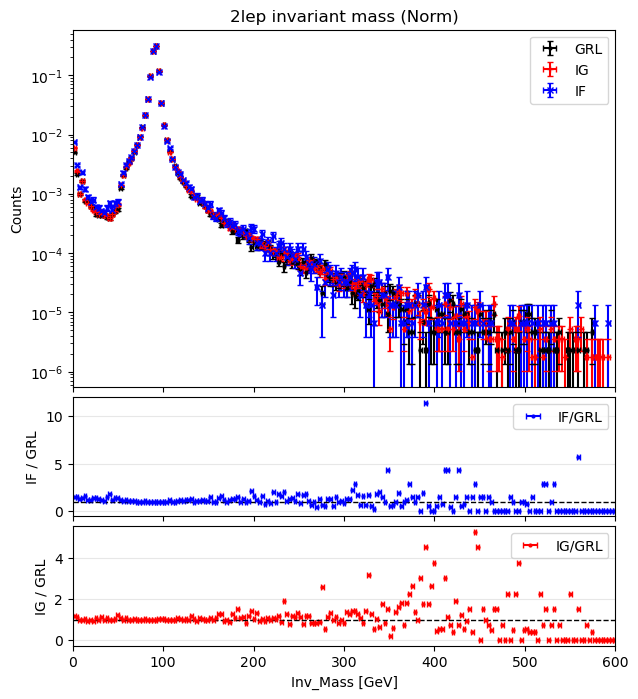

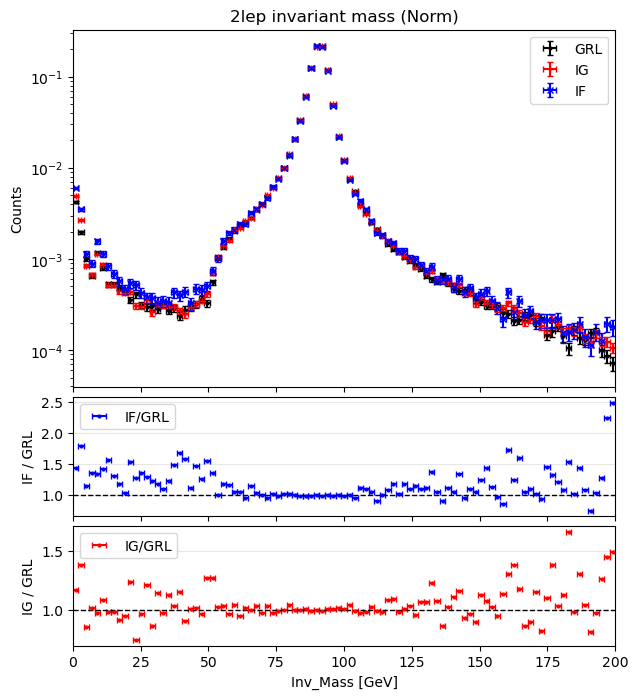

### Second run: QCD jets on the single-jet trigger

Now the same treatment on the other stream. Setting `ty = 'jet'` switches to the QCD samples, and `tit = 'J'` requires the single-jet trigger together with a jet above 500 GeV comfortably clear of the turn-on region, so we are not measuring the trigger instead of the detector.

Two quantities are plotted:

1. **Jet multiplicity**, over 0-50 and again over 0-10. The wide range catches events with an implausible number of reconstructed jets; the narrow one checks the bulk.
2. **Missing transverse energy**, over 0-5000 GeV, 0-1000 GeV and 50-400 GeV. The widest range is the trap nothing physical belongs out there, so anything that appears is a candidate pathology.

In [ ]:
# Analysis configuration flags

ty = 'jet'   # object type to analyse: 'lep' (dileptons), 'jet' (QCD jets), or 'both'
tit = 'J'    # jet trigger to require: 'J' (single-jet) or 'met' for met cuts

run()

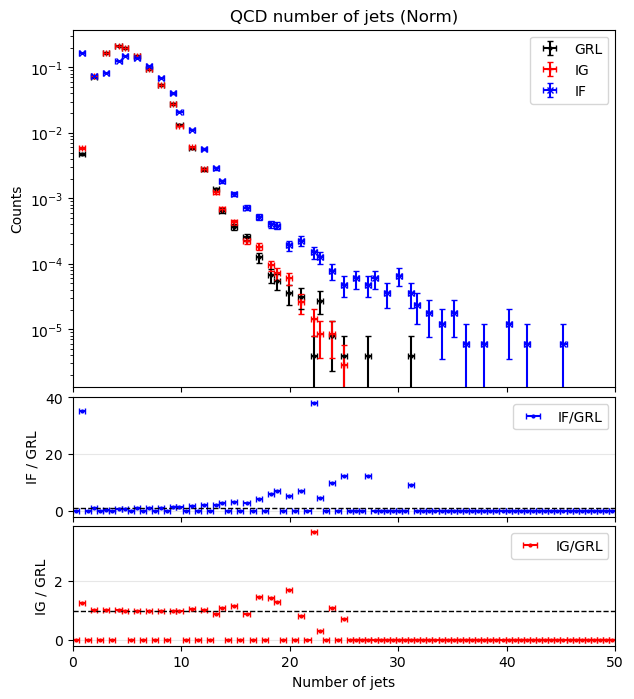

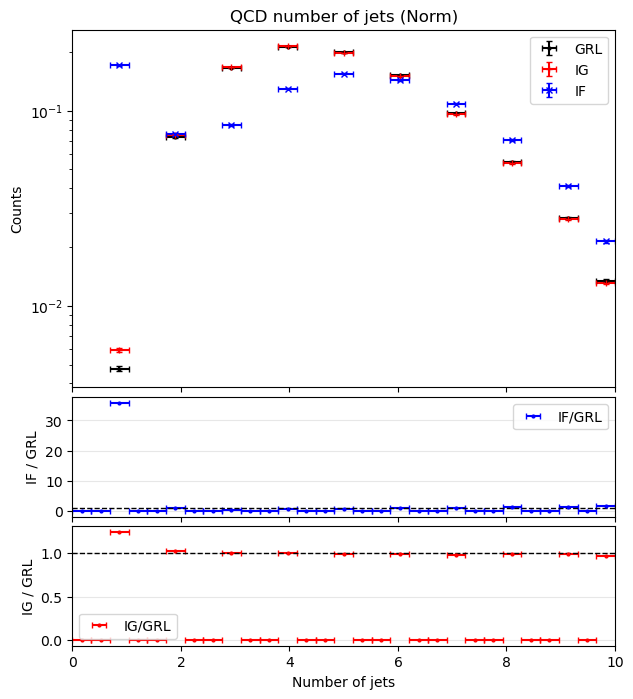

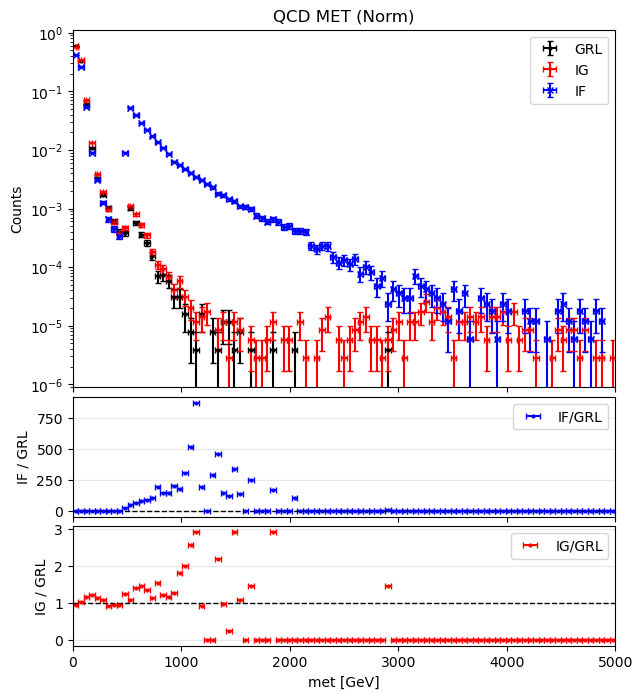

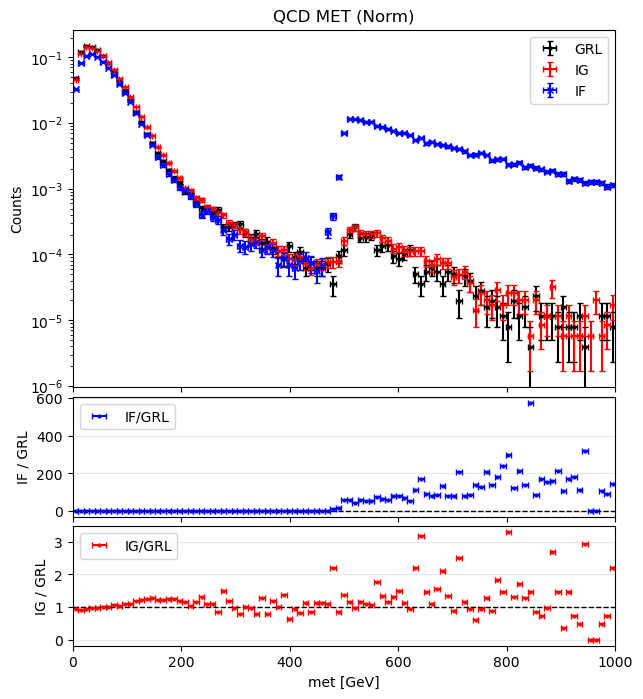

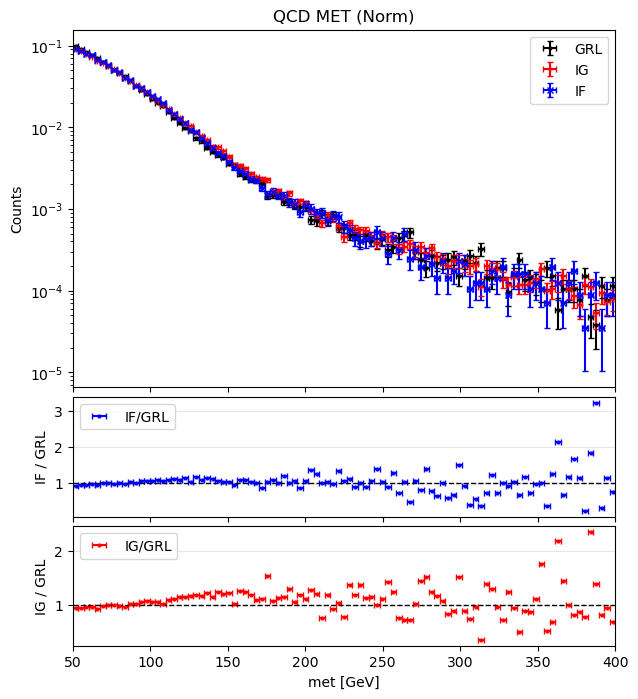

### Third run: QCD jets on the MET trigger

The same stream, entered through a different door. `tit = 'met'` drops the single-jet requirement in favour of the MET trigger and a cut at MET > 300 GeV, so events are now selected *on* missing energy rather than on a hard jet which is precisely the quantity a calorimeter fault distorts. If one selection is keeping noise bursts that another rejects, this is where it should show most clearly.

The same jet-multiplicity and MET plots follow, and the comparison worth making is against the previous run: a difference between the selections that survives both triggers is a property of the data, while one that appears under only one is more likely a feature of that trigger's event mix.

In [ ]:
# Analysis configuration flags

ty = 'jet'   # object type to analyse: 'lep' (dileptons), 'jet' (QCD jets), or 'both'
tit = 'met'    # jet trigger to require: 'J' (single-jet) or 'met' for met cuts

run()

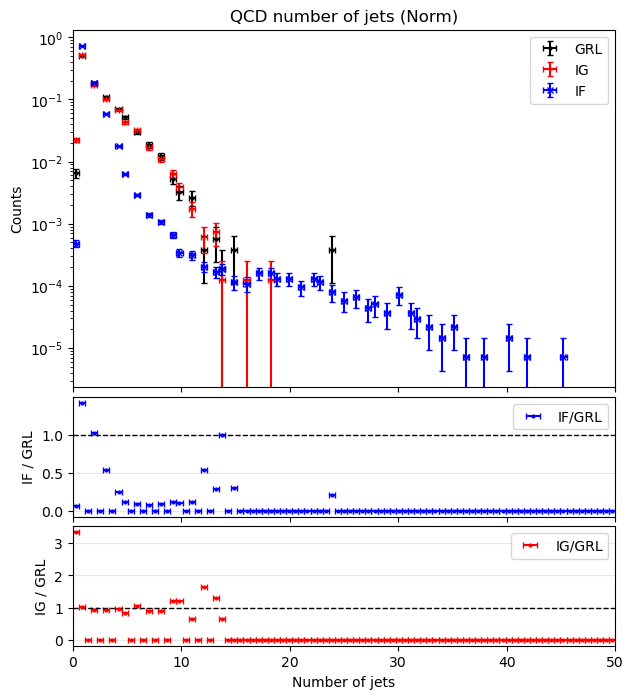

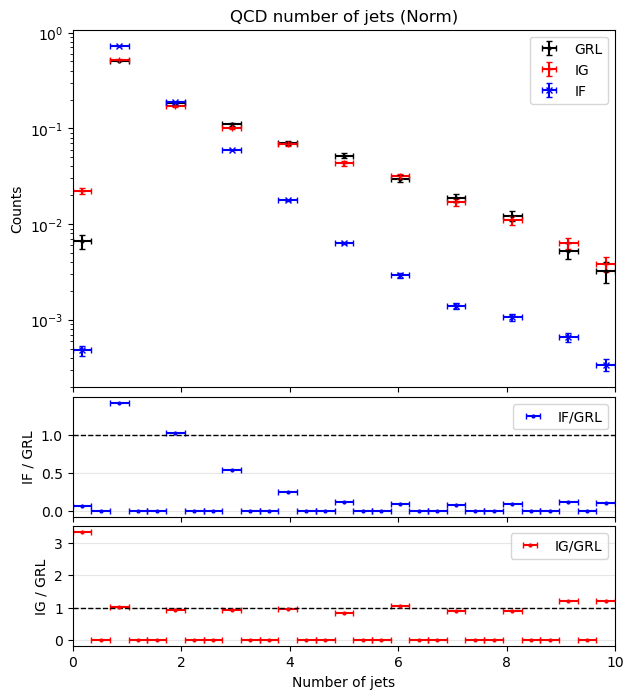

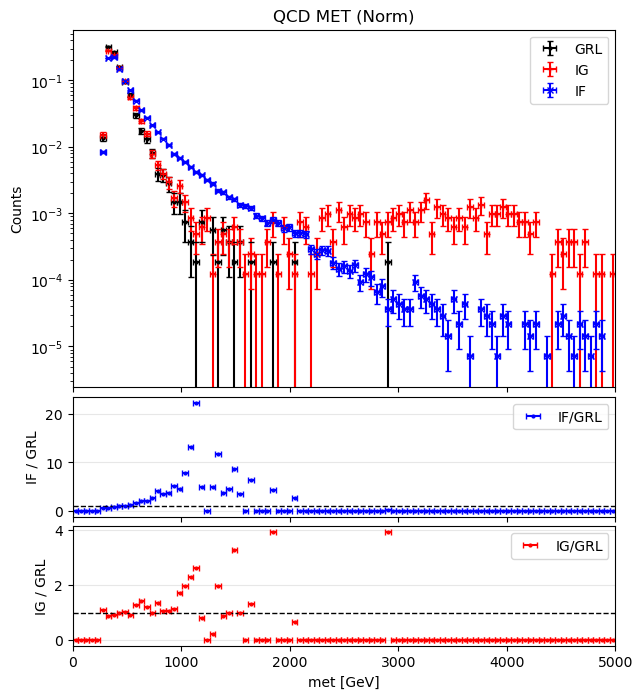

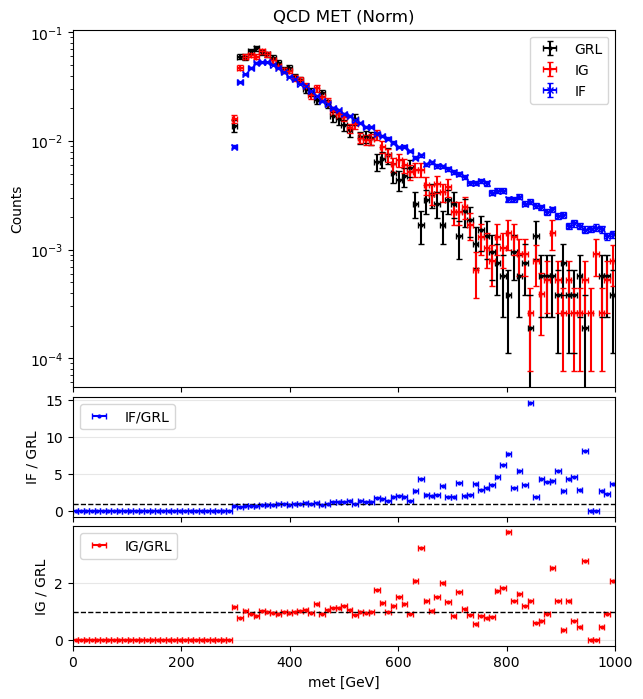